# Table of Contents


<!-- *   [Data Hosting & Package Installs](#data-installs) -->
*   [Overview](#overview)
  - [Glossary](#glossary)
  - [Bioacoustics and Biodiversity](#bio_and_bio)
  - [Agile Modeling for Bioacoustics](#agile_modeling)
*   [Climate Impact](#climate-impact)
*   [Target Audience](#target-audience)
*   [Data Description](#data-description)
*   [Methodology](#methodology)
  - [Software Requirements](#software-requirements)
  - [Embed the Search Dataset](#embed_data)
  - [Audio Similarity Search](#similarity-search)
  - [Active Learning](#active-learning)
*   [Discussion](#discussion)
*   [References](#references)


In [1]:
# @title Imports {vertical-output: true}

import collections
import os

from etils import epath
from IPython.display import HTML
import matplotlib.pyplot as plt
from ml_collections import config_dict
import numpy as np
import tensorflow as tf
import tqdm

# perch-hoplite: the agile modeling workflow.
from perch_hoplite.agile import audio_loader
from perch_hoplite.agile import classifier
from perch_hoplite.agile import classifier_data
from perch_hoplite.agile import colab_utils
from perch_hoplite.agile import embed
from perch_hoplite.agile import embedding_display
from perch_hoplite.agile import ingest_annotations
from perch_hoplite.agile import source_info
from perch_hoplite.db import brutalism
from perch_hoplite.db import interface
from perch_hoplite.db import score_functions
from perch_hoplite.db import search_results
from perch_hoplite.zoo import model_configs

print('TensorFlow version :', tf.__version__)
print('NumPy version      :', np.__version__)

# A GPU makes the embedding step considerably faster. Every other step in this
# tutorial is quick on CPU, so a CPU-only runtime is perfectly usable.
gpus = tf.config.list_physical_devices('GPU')
if gpus:
  print(f'GPU available      : yes ({len(gpus)} device(s))')
else:
  print('GPU available      : no (CPU only - this is fine for this tutorial)')

TensorFlow version : 2.21.0
NumPy version      : 2.5.4
GPU available      : no (CPU only - this is fine for this tutorial)


In [2]:
# @title Load the pre-trained embedding model {vertical-output: true}

# Like the original version of this tutorial, we use one model throughout:
# Perch v8, the direct successor to the v4 model the 2023 version loaded
# from TFHub. perch-hoplite also supports other embedding models (Perch 2.0,
# BirdNET, SurfPerch, ...), but embeddings from different models are not
# comparable, so each model needs its own database built from scratch.
model_choice = 'perch_8'

preset_info = model_configs.get_preset_model_config(model_choice)

print(f'Preset           : {model_choice}')
print(f'Model class key  : {preset_info.model_key}')
print(f'Embedding dim    : {preset_info.embedding_dim}')
print(f'Window size (s)  : {preset_info.model_config.window_size_s}')
print(f'Hop size (s)     : {preset_info.model_config.hop_size_s}')
print(f'Sample rate (Hz) : {preset_info.model_config.sample_rate}')

# Convenience aliases used throughout the rest of the notebook.
SAMPLE_RATE = int(preset_info.model_config.sample_rate)
WINDOW_SIZE_S = float(preset_info.model_config.window_size_s)
HOP_SIZE_S = float(preset_info.model_config.hop_size_s)

# The model is downloaded from Kaggle Models on first use, then cached for the
# rest of the session.
print('\nLoading model (the first run downloads it from Kaggle)...')
embedding_model = preset_info.load_model()

# Smoke test: embed five seconds of silence and check the output shape.
silence = np.zeros([int(SAMPLE_RATE * WINDOW_SIZE_S)], dtype=np.float32)
test_embedding = embedding_model.embed(silence).embeddings

print('Model loaded successfully.')
print(f'Test embedding shape: {test_embedding.shape} '
      f'-> {test_embedding.shape[-1]} numbers describing '
      f'{WINDOW_SIZE_S:.0f}s of audio')

Preset           : perch_8
Model class key  : taxonomy_model_tf
Embedding dim    : 1280
Window size (s)  : 5.0
Hop size (s)     : 5.0
Sample rate (Hz) : 32000

Loading model (the first run downloads it from Kaggle)...


c:\agile\.venv\Lib\site-packages\perch_hoplite\zoo\zoo_interface.py:159: UserWarning: 'where' used without 'out', expect uninitialized memory in output. If this is intentional, use out=None.
  framed_audio = np.divide(framed_audio, peak_norm, where=(peak_norm > 0.0))


Model loaded successfully.
Test embedding shape: (1, 1, 1280) -> 1280 numbers describing 5s of audio


In [3]:
# @title Connect to the embedding database {vertical-output: true}

# @markdown A name identifying who is applying labels in this session. In a real
# @markdown project this records the provenance of every annotation.
annotator_id = 'summer_school_participant'  # @param {type: 'string'}

# @markdown Where the audio lives and where the database is written. The audio
# @markdown itself is downloaded in a later cell; this only records the location.
audio_base_path = './data/audio'  # @param {type: 'string'}
audio_file_glob = '*/*.wav'  # @param {type: 'string'}
db_path = './content/osa_db'  # @param {type: 'string'}

audio_glob = source_info.AudioSourceConfig(
    dataset_name='silencio',
    base_path=audio_base_path,
    file_glob=audio_file_glob,
    min_audio_len_s=1.0,
    # -2 means "use the model's own sample rate", i.e. 32 kHz.
    target_sample_rate_hz=-2,
    shard_len_s=60.0,
)

configs = colab_utils.load_configs(
    source_info.AudioSources((audio_glob,)),
    db_path=db_path,
    model_config_key=model_choice,
)

db = configs.db_config.load_db()

print('Database ready at    :', db_path)
print('Embeddings stored    :', db.count_embeddings())
print('(0 is expected on a fresh run. If you loaded a prepared database')
print('above, you should instead see the full count already.)')

Database ready at    : ./content/osa_db
Embeddings stored    : 0
(0 is expected on a fresh run. If you loaded a prepared database
above, you should instead see the full count already.)


In [4]:
# @title Check the downloaded audio {vertical-output: true}

import glob

found = sorted(glob.glob(os.path.join(audio_base_path, audio_file_glob)))
print(f'Audio files matching {audio_file_glob!r} under {audio_base_path}:')
for fp in found:
  print(f'  {os.path.relpath(fp, audio_base_path)}')
print(f'\n{len(found)} file(s) found.')

if not found:
  raise FileNotFoundError(
      'No audio found. Re-run the download cell above, and check that '
      f'audio_base_path ({audio_base_path!r}) and audio_file_glob '
      f'({audio_file_glob!r}) match where the files were actually written.')

# The configuration that will be recorded alongside these embeddings.
print('\nEmbedding configuration stored with the database:')
print(f'  model            : {model_choice}')
print(f'  embedding dim    : {preset_info.embedding_dim}')
print(f'  window / hop (s) : {WINDOW_SIZE_S} / {HOP_SIZE_S}')
print(f'  sample rate (Hz) : {SAMPLE_RATE}')

Audio files matching '*/*.wav' under ./data/audio:
  H23\H23_20230423_183500.WAV
  H23\H23_20230424_172000.WAV
  H23\H23_20230425_174000.WAV
  H23\H23_20230425_174500.WAV
  H23\H23_20230425_180000.WAV
  H23\H23_20230425_184000.WAV
  H23\H23_20230426_183000.WAV
  H23\H23_20230506_182500.WAV
  H23\H23_20230509_174000.WAV
  H23\H23_20230510_181500.WAV
  H23\H23_20230511_173000.WAV
  H23\H23_20230511_173500.WAV
  H23\H23_20230511_185500.WAV
  H23\H23_20230513_175500.WAV
  H23\H23_20230513_182000.WAV
  H23\H23_20230513_184000.WAV
  H23\H23_20230515_183500.WAV
  H23\H23_20230516_183500.WAV
  H23\H23_20230518_174000.WAV
  H23\H23_20230518_182500.WAV
  H23\H23_20230520_181000.WAV
  H23\H23_20230520_185000.WAV
  H23\H23_20230521_174000.WAV
  H64\H64_20230424_051500.WAV
  H64\H64_20230424_052000.WAV
  H64\H64_20230428_190000.WAV
  H64\H64_20230501_185500.WAV
  H75\H75_20230514_184000.WAV
  H75\H75_20230519_051000.WAV
  H80\H80_20230428_063000.WAV
  H80\H80_20230514_180500.WAV
  H80\H80_20230514_

### Embed the search dataset

`EmbedWorker` walks every audio file matching our glob, splits it into five-second windows, runs each window through the model, and writes the resulting 1280-number vectors into the database.

This is the expensive step, and the only one in this tutorial that genuinely benefits from a GPU. It is also the step that dominates the energy cost of the whole workflow — which is why we measure it with CodeCarbon later on.

The important property is that **you pay for it only once.** Every later step — searching, labeling, training, retraining — reads the stored embeddings instead of touching the audio again. That is what makes the iterative loop at the heart of agile modeling practical: you can retrain and re-search in seconds, because the heavy computation is already done and saved.

In [5]:
# @title Embed the audio {vertical-output: true}

n_existing = db.count_embeddings()

worker = embed.EmbedWorker(
    audio_sources=configs.audio_sources_config,
    db=db,
    model_config=configs.model_config,
)

print('Embedding audio.')
print('On a T4 GPU this takes a couple of minutes; on CPU it is slower')


Embedding audio.
On a T4 GPU this takes a couple of minutes; on CPU it is slower


In [6]:


worker.process_all(target_dataset_name=audio_glob.dataset_name, handle_duplicates="skip")

n_embeddings = db.count_embeddings()
print('\nEmbedding complete.')
print('Total embeddings in database:', n_embeddings)





Adding deployments...


100%|██████████| 104/104 [00:00<00:00, 738.08it/s]



Adding recordings...


100%|██████████| 104/104 [00:00<00:00, 12657.27it/s]



Adding annotations...

Embedding audio...


  0%|          | 0/104 [00:00<?, ?it/s]c:\agile\.venv\Lib\site-packages\perch_hoplite\zoo\zoo_interface.py:159: UserWarning: 'where' used without 'out', expect uninitialized memory in output. If this is intentional, use out=None.
  framed_audio = np.divide(framed_audio, peak_norm, where=(peak_norm > 0.0))
100%|██████████| 104/104 [04:51<00:00,  2.81s/it]



Embedding complete.
Total embeddings in database: 1248


In [7]:
db.count_embeddings()

1248

### Check that the embeddings work

Before going further, a quick sanity check. We take one window from the database and ask for its nearest neighbours.

If the database and its vector index are working, this returns a ranked list of other windows that sound similar. It is a small test, but it exercises the whole machinery that the rest of the tutorial depends on — and it is much easier to debug here than after you have spent twenty minutes labeling.

In [8]:
# @title Sanity check: search the database {vertical-output: true}

num_embeddings = db.count_embeddings()
print(f'Embeddings stored : {num_embeddings}')
print(f'Audio covered     : ~{num_embeddings * WINDOW_SIZE_S / 60:.0f} minutes')

# Pick one stored window and find its nearest neighbours.
example_window_id = db.match_window_ids(limit=1)[0]
example_embedding = db.get_embedding(example_window_id)

results = brutalism.brute_search(
    db,
    query_embedding=example_embedding,
    search_list_size=10,
    score_fn=np.dot,
)

print('\nTen windows most similar to one randomly chosen window:')
print([int(r.window_id) for r in results])
print('\nIf you see a list of window ids above, everything is working.')

Embeddings stored : 1248
Audio covered     : ~104 minutes

Ten windows most similar to one randomly chosen window:
[1, 4, 8, 11, 6, 5, 183, 3, 7, 10]

If you see a list of window ids above, everything is working.


In [14]:


def get_recording_id(filename):
    recordings = db.get_all_recordings()
    result = list(filter(lambda x: x.filename == filename, recordings))
    if result:
        result = result[0]
        return result.id
    else:
        return None


In [18]:
db.get_all_deployments()

[Deployment(id=1, name='H75', project='silencio', latitude=None, longitude=None),
 Deployment(id=2, name='H82', project='silencio', latitude=None, longitude=None),
 Deployment(id=3, name='H23', project='silencio', latitude=None, longitude=None),
 Deployment(id=4, name='H96', project='silencio', latitude=None, longitude=None),
 Deployment(id=5, name='H87', project='silencio', latitude=None, longitude=None),
 Deployment(id=6, name='H80', project='silencio', latitude=None, longitude=None),
 Deployment(id=7, name='H64', project='silencio', latitude=None, longitude=None)]

In [13]:
db.get_all_recordings()

[Recording(id=1, filename='H23/H23_20230423_183500.WAV', datetime=None, deployment_id=3),
 Recording(id=2, filename='H23/H23_20230424_172000.WAV', datetime=None, deployment_id=3),
 Recording(id=3, filename='H23/H23_20230425_174000.WAV', datetime=None, deployment_id=3),
 Recording(id=4, filename='H23/H23_20230425_174500.WAV', datetime=None, deployment_id=3),
 Recording(id=5, filename='H23/H23_20230425_180000.WAV', datetime=None, deployment_id=3),
 Recording(id=6, filename='H23/H23_20230425_184000.WAV', datetime=None, deployment_id=3),
 Recording(id=7, filename='H23/H23_20230426_183000.WAV', datetime=None, deployment_id=3),
 Recording(id=8, filename='H23/H23_20230506_182500.WAV', datetime=None, deployment_id=3),
 Recording(id=9, filename='H23/H23_20230509_174000.WAV', datetime=None, deployment_id=3),
 Recording(id=10, filename='H23/H23_20230510_181500.WAV', datetime=None, deployment_id=3),
 Recording(id=11, filename='H23/H23_20230511_173000.WAV', datetime=None, deployment_id=3),
 Recordi

In [25]:
import pandas as pd
from perch_hoplite.db.datatypes import LabelType, Annotation

df = pd.read_csv("./data/audio/annotations.csv")
df["filename"] = df["audiofilename"].str.split("/", n=1).str[-1]
files = df["filename"].to_list()
ids = []
for file in files:
    ids.append(get_recording_id(file))
dfsubset = df[["start", "end"]]

df["recording_id"] = df["filename"].apply(get_recording_id)
df["offsets"] = dfsubset.apply(list,axis=1)
df["label_type"] = LabelType.POSITIVE


df = df.rename(columns = {'label:species' : 'label'} )
df["provenance"] = "silencio"

df = df[["recording_id", "offsets", "label", "label_type", "provenance"]]



db.get_all_annotations()


[]

In [28]:
print('Annotations before saving :', len(db.get_all_annotations()))

for row in df.itertuples():
    db.insert_annotation(row.recording_id, row.offsets, row.label, row.label_type, row.provenance)

print('Annotations after saving  :', len(db.get_all_annotations()))


Annotations before saving : 0
Annotations after saving  : 697


In [29]:
db.get_all_annotations()

[Annotation(id=1, recording_id=1, offsets=[0.376343955, 59.784925478], label='DENMIC', label_type=<LabelType.POSITIVE: 1>, provenance='silencio'),
 Annotation(id=2, recording_id=2, offsets=[7.043008307, 7.48655654], label='DENEBR', label_type=<LabelType.POSITIVE: 1>, provenance='silencio'),
 Annotation(id=3, recording_id=2, offsets=[20.483068078, 21.450809678], label='DENMIC', label_type=<LabelType.POSITIVE: 1>, provenance='silencio'),
 Annotation(id=4, recording_id=2, offsets=[33.913236966, 34.464312043], label='DENEBR', label_type=<LabelType.POSITIVE: 1>, provenance='silencio'),
 Annotation(id=5, recording_id=2, offsets=[40.247524295, 41.000212206], label='DENEBR', label_type=<LabelType.POSITIVE: 1>, provenance='silencio'),
 Annotation(id=6, recording_id=2, offsets=[41.71257755, 42.734082572], label='DENEBR', label_type=<LabelType.POSITIVE: 1>, provenance='silencio'),
 Annotation(id=7, recording_id=2, offsets=[49.499303557, 50.762743978], label='DENEBR', label_type=<LabelType.POSITIV

<a name=similarity-search></a>
## Audio Similarity Search

In the previous section we generated a set of embeddings for our search corpus as well as for our Wood Thrush query.  In this section we will 'search' within the search corpus to find examples that are similar to our query, and we'll manually label each sample as 'Wood Thrush' or 'Unknown'.  These labeled samples then get saved and will be used as training data for the linear classifier in the next section.

Recall that an *embedding* is simply a vector (point) in some high dimensional space.  The similarity search we implement relies of Euclidean distance between two vectors. Other metrics can be used to compare two vectors, such as cosine similarity or Maximum Inner Product (MIP).

**Note:** In practice, we end up looping through this section repeatedly with different query samples (if we have them) and different search parameters.  That helps us generate a robust training set.

### Define the target class

We specify the class we want to find in the search corpus. Here that is the Wood Thrush, written as **`woothr`** — its [eBird species code](https://science.ebird.org/en/use-ebird-data).

**Why a code instead of "Wood Thrush"?** Because the Powdermill ground-truth annotations use these codes, and we want our labels to line up with theirs when we evaluate the classifier later. This is a small detail with a large practical lesson: label vocabularies are how ecological datasets interoperate. A project that invents its own names for species produces results nobody else can combine with theirs, and merging them afterwards is tedious, manual, and error-prone. Agreeing on a shared vocabulary at the start costs nothing; retrofitting one costs weeks.

Note also that we now need only the **positive** label. The original tutorial asked you to label each clip "Wood Thrush" or "Unknown". `perch-hoplite` records a positive label when you mark a result, and treats unmarked results from your searches as *weak negatives* — likely-but-unconfirmed negatives, which are down-weighted during training. This reflects how annotation actually works: an expert confidently says "that is a Wood Thrush" far more often than they can confidently say "there is definitely no Wood Thrush anywhere in these five seconds."

In [7]:
# @title Define the target label {vertical-output: true}

# @markdown The eBird species code for the Wood Thrush.
target_label = 'DENEBR'  # @param {type: 'string'}

# Loads the audio behind a search result so we can plot and play it.
audio_filepath_loader = audio_loader.make_filepath_loader(
    audio_sources=configs.audio_sources_config,
    window_size_s=WINDOW_SIZE_S,
    sample_rate_hz=SAMPLE_RATE,
)

print('Target label :', target_label)
print('Annotator id :', annotator_id)

Target label : DENEBR
Annotator id : summer_school_participant


#### Nature detour: a glance at the Wood Thrush

<a name=active-learning></a>
## Train a Linear Classifier

In the last stage, we labeled samples from the search dataset as matches (by similarity comparison with the queries) for each of our target classes. We will now train a simple linear model using those bootstrapped (labeled) data points from the search dataset.

**Important:** in order to be able to train the linear model, we need ~10-12 examples from each class, in our case 'Wood Thrush' and 'Unknown'. If you encounter an error in this section when training the model, you likely did not generate a sufficient amount of labeled data. Please go back to the [Top-k Search](#top-k-search) section and choose a new value of the `target_score` attribute.

In [30]:
# @title Prepare the labeled data {vertical-output: true}

# Check that labels exist before doing anything else. Forgetting to click the
# label buttons, or forgetting to run the save cell, is the most common thing
# go wrong in this notebook - and the error it otherwise produces is useless.
existing_labels = db.get_all_labels()

if not existing_labels:
  raise ValueError(
      'No labels found in the database.\n\n'
      'The classifier has nothing to learn from. To create labels:\n'
      '  1. Scroll up and re-run the search cell.\n'
      '  2. In the results, CLICK THE LABEL BUTTON on every clip where\n'
      f'     you can hear the target species ({target_label}).\n'
      '  3. Run the "Save the labels" cell straight afterwards.\n'
      '  4. Repeat until you have at least 10 positives, then come back.\n\n'
      'Note: re-running the search cell discards any labels you have not\n'
      'saved yet, so save before searching again.'
  )

label_counts = db.count_each_label()
print('Labels in the database:')
for label, count in label_counts.items():
  print(f'  {label:12s} {count}')

#n_target = label_counts.get(target_label, 0)


# @markdown Fraction of labeled examples used for training; the rest are held
# @markdown out to evaluate the model. With ~10 positives, 0.8 holds out two
# @markdown of them - the minimum this library needs to compute every metric.
train_ratio = 0.8  # @param {type: 'number'}

# @markdown Batch sizes for training and for weak negatives.
batch_size = 128  # @param {type: 'number'}
weak_negatives_batch_size = 128  # @param {type: 'number'}

data_manager = classifier_data.AgileDataManager(
    target_labels=None,  # auto-populated from the labels in the database
    db=db,
    train_ratio=train_ratio,
    min_eval_examples=1,
    batch_size=batch_size,
    weak_negatives_batch_size=weak_negatives_batch_size,
    rng=np.random.default_rng(seed=5),
)

print('\nTraining for target labels:', data_manager.get_target_labels())
train_ids, eval_ids = data_manager.get_train_test_split()
print(f'Training examples : {len(train_ids)}')
print(f'Held-out examples : {len(eval_ids)}')



Labels in the database:
  DENEBR       43
  DENMIC       143
  ELAPER       33
  ENGPUS       431
  LEPFRA       47

Training for target labels: ('DENEBR', 'DENMIC', 'ELAPER', 'ENGPUS', 'LEPFRA')
Training examples : 782
Held-out examples : 224


### Train a simple linear model using the labeled embeddings

We use the following hyperparameters which should serve as reasonably performing defaults to train this linear model (classifier):

- `batch_size`: 12
- `num_epochs`: 128
- `num_hiddens`: -1 (to match the dimens of the embeddings)
- `learning_rate`: 0.001

Additionally, we compute the following metrics to measure the "goodness" of the trained model:
- `acc`: overall accuracy
- `auc_roc`: AUC ROC, or area under the receiving curve
- `cmAP`: mean average precision averaged across species
- `maps`: mean average precision for each class

In [31]:
# @title Classifier hyperparameters {vertical-output: true}

# @markdown These defaults work well and should not need tuning.
learning_rate = 1e-3  # @param {type: 'number'}
num_train_steps = 128  # @param {type: 'number'}

# @markdown How much to trust unlabeled results as negatives. Low by design:
# @markdown an unlabeled result is a guess, not an observation.
weak_neg_weight = 0.05  # @param {type: 'number'}

print(f'learning rate    : {learning_rate}')
print(f'training steps   : {num_train_steps}')
print(f'weak neg weight  : {weak_neg_weight}')

learning rate    : 0.001
training steps   : 128
weak neg weight  : 0.05


In [32]:
# @title Train the linear classifier {vertical-output: true}

linear_classifier, eval_scores = classifier.train_linear_classifier(
    data_manager=data_manager,
    learning_rate=learning_rate,
    weak_neg_weight=weak_neg_weight,
    num_train_steps=num_train_steps,
)

print('\nTraining complete.')

Loss 0.04399695: 100%|██████████| 128/128 [00:04<00:00, 30.00it/s]



Training complete.


#### Model performance

Three numbers are reported:

* **top-1 accuracy** — how often the highest-scoring label is correct.
* **ROC-AUC** — the probability that a randomly chosen positive scores higher than a randomly chosen negative. 0.5 is a coin flip; 1.0 is perfect.
* **cMAP** — mean average precision averaged over classes; sensitive to how well the positives are ranked.

**Read these with suspicion.** They are computed on held-out examples drawn from the data *you labeled*, and you found that data by searching for things similar to your query and labeling what you recognised. That is not a random sample of the soundscape — it is enriched for clear examples of one species, and it contains almost nothing from the long, dull stretches that make up most real recordings.

So a ROC-AUC of 0.95 here does **not** mean "95% reliable in the field." It means the classifier separates the kinds of examples you chose to show it. Performance on the full corpus is normally worse, sometimes much worse.

This is not a flaw in this tutorial — it is the standard failure mode of active learning, and knowing it exists is a large part of using these methods responsibly. We measure the real gap against expert ground truth further down.

In [33]:
# @title Show the metrics {vertical-output: true}

import math


def _fmt(value):
  """Format a metric, making 'could not be computed' explicit."""
  if value is None or (isinstance(value, float) and math.isnan(value)):
    return 'not computable'
  return f'{value:.3f}'


top1 = eval_scores['top1_acc']
rocauc = eval_scores['roc_auc']
cmap = eval_scores['cmap']

print(f'top-1 accuracy : {_fmt(top1)}')
print(f'ROC-AUC        : {_fmt(rocauc)}')
print(f'cMAP           : {_fmt(cmap)}')

print('\nLabels used for training:')
for label, count in db.count_each_label().items():
  print(f'  {label:12s} {count}')

def _is_nan(v):
  return v is None or (isinstance(v, float) and math.isnan(v))


if all(_is_nan(v) for v in (top1, rocauc, cmap)):
  print('\n' + '=' * 68)
  print('THE METRICS COULD NOT BE COMPUTED')
  print('=' * 68)
  print('Nothing crashed, and the model did train. But the evaluation')
  print('split did not contain both a positive and a negative example,')
  print('so there is nothing to measure the model against.\n')
  print('This matters more than it might appear. A model you cannot')
  print('evaluate is a model you cannot trust, however confident its')
  print('outputs look - and the cells below will happily produce')
  print('detections regardless. Do not believe them yet.\n')
  print('Fix: return to the search and labeling steps, collect at least')
  print('10 positive AND 10 negative labels, and retrain.')
else:
  if _is_nan(cmap):
    print('\nAbout the blank cMAP: this library only computes it when')
    print('the held-out split contains at least TWO positive clips;')
    print('yours holds fewer, so cMAP is skipped. The top-1 and ROC-AUC')
    print('numbers above are still valid. To get cMAP too, label a few')
    print('more positives, or lower train_ratio in the "Prepare the')
    print('labeled data" cell, and retrain.')
  if not _is_nan(rocauc):
    if rocauc < 0.9:
      print(f'\nROC-AUC is {rocauc:.3f}, below the 0.9 rule of thumb.')
      print('Before concluding the method does not work, try: labeling')
      print('more examples, enabling target sampling to find harder')
      print('cases, or choosing a cleaner query window.')
    else:
      print(f'\nROC-AUC of {rocauc:.3f} looks healthy - but read the')
      print('note above about why this number flatters the model.')

# Save the classifier so it can be reused without retraining.
classifier_path = os.path.join(db_path, 'agile_classifier.pt')
linear_classifier.save(classifier_path)
print(f'\nClassifier saved to {classifier_path}')

top-1 accuracy : 0.933
ROC-AUC        : 0.973
cMAP           : 0.919

Labels used for training:
  DENEBR       43
  DENMIC       143
  ELAPER       33
  ENGPUS       431
  LEPFRA       47

ROC-AUC of 0.973 looks healthy - but read the
note above about why this number flatters the model.

Classifier saved to ./content/osa_db\agile_classifier.pt


### The Active Learning Loop: Generating more training examples

It is possible, and even likely, that your first pass through the data yielded a model that could be improved, possibly with a low AUC-ROC, or poor performance in one particular class.  To improve the model, we need to generate additional interesting labeled examples from each class.  There are two ways we can proceed:

1. Go back to the audio search step and either use a new query example (if you have one), or play with the `target_score` param in the top-k search cell.
2. Now that we have trained a linear model, we can examine that model's outputs to help us surface new examples from th search corpus.

Both methods are perfectly reasonable, there is no right answer here!  If you'd like try the second method, proceed to the next cell.

### Generate new samples using logit scores

Most models output some notion of 'activation' per class, which can be thought of as some form of confidence score.  When you run a new sample through a model, the resulting activation value is called is a **logit**.  In the next cell we will surface new examples by looking for points in the search corpus that yield high logit scores for a given target class.  Intuitively, these are points that our linear model is very excited about, and therefore the resulting points are likely to be relevant to our task.

This method is similar to our top-k search method above.  We can input a `target_logit`, which will be used to surface points with a logit score that is close to the `target_logit`.  In a later cell, we show a histogram of all logit scores to indicate what the useful values of `target_logit` might be.  The first time through this cell, set `target_logit = None` to find matches with the highest logit.

Another good choice is `target_logit = 0.0`. This corresponds to the data where the model is most uncertain - labeling this data is a common active learning strategy called **margin sampling** and can help produce good models quickly.




In [35]:
# @title Find new examples using the classifier {vertical-output: true}

# @markdown Number of results to surface.
num_results = 5  # @param {type: 'number'}

# @markdown If checked, look for examples the model is *uncertain* about
# @markdown (margin sampling) rather than the ones it is most confident about.
margin_sampling = True  # @param {type: 'boolean'}

# @markdown The logit to aim for when margin sampling. 0.0 is the decision
# @markdown boundary - where the model is maximally unsure.
margin_target_score = 0.0  # @param {type: 'number'}

# @markdown How many database entries to search over.
sample_size = 1_000_000  # @param {type: 'number'}

target_label_idx = data_manager.get_target_labels().index(target_label)
class_query = linear_classifier.beta[:, target_label_idx]
bias = linear_classifier.beta_bias[target_label_idx]

score_fn = score_functions.get_score_fn(
    'dot', bias=bias,
    target_score=margin_target_score if margin_sampling else None)

results = brutalism.threaded_brute_search(
    db, class_query, num_results, score_fn=score_fn, sample_size=sample_size)

print(f'Returned {len(results.search_results)} results.')
print('Now label these below, then retrain. This is the active learning loop.')

Returned 5 results.
Now label these below, then retrain. This is the active learning loop.


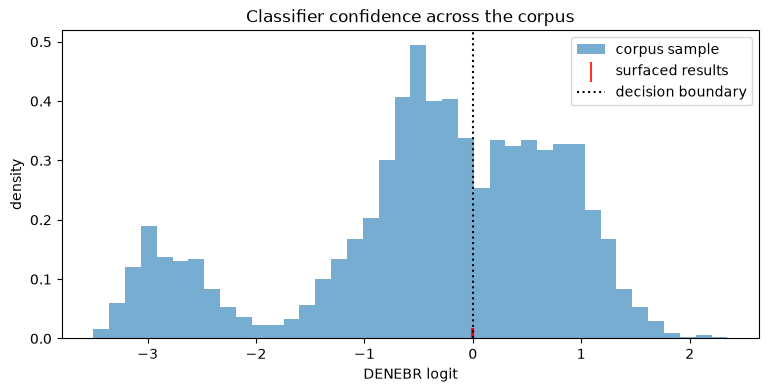

41.2% of sampled windows score above the decision boundary.
If that number looks implausibly high for one species in one forest, it probably is - a useful early warning of a poor classifier.


In [36]:
# @title Plot the classifier logits {vertical-output: true}

scores = brutalism.get_random_embedding_scores(
    db,
    class_query,
    score_fn=score_functions.get_score_fn('dot', bias=bias),
    sample_size=2048,
    rng_seed=42,
)

plt.figure(figsize=(9, 4))
plt.hist(scores, bins=40, density=True, alpha=0.6, label='corpus sample')

hit_scores = [r.sort_score for r in results.search_results]
plt.scatter(hit_scores, np.zeros_like(hit_scores), marker='|',
            color='r', alpha=0.8, s=200, label='surfaced results')
plt.axvline(0.0, color='k', linestyle=':', label='decision boundary')

plt.xlabel(f'{target_label} logit')
plt.ylabel('density')
plt.title('Classifier confidence across the corpus')
plt.legend()
plt.show()

above = (scores > 0).mean()
print(f'{above * 100:.1f}% of sampled windows score above the decision '
      'boundary.')
print('If that number looks implausibly high for one species in one forest, '
      'it probably is - a useful early warning of a poor classifier.')

Page 1 of 1
--------------------------------------------------------------------------------



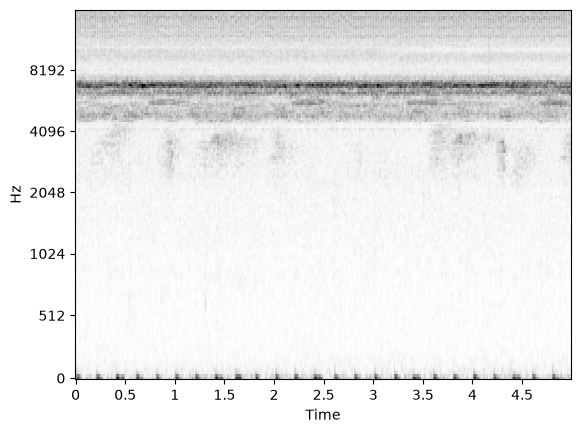

dataset name : osa
source uri   : swamp/sw2/1Jsw2_20261010_020000.wav
offset_s     : 45.00
score        : -0.00


GridspecLayout(children=(Button(description='DENEBR', layout=Layout(grid_area='widget001'), style=ButtonStyle(…


--------------------------------------------------------------------------------


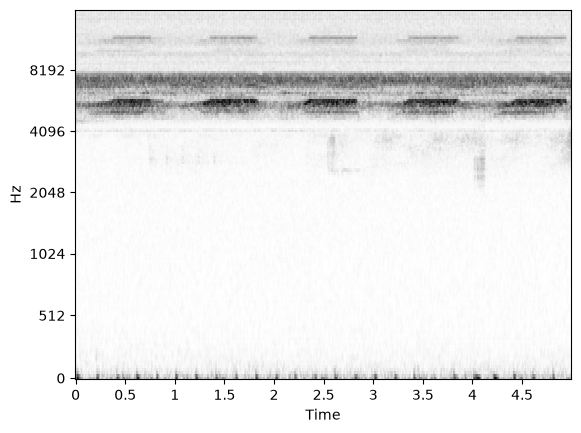

dataset name : osa
source uri   : swamp/sw2/1Jsw2_20261009_030000.wav
offset_s     : 10.00
rank         : 1
score        : -0.00


GridspecLayout(children=(Button(description='DENEBR', layout=Layout(grid_area='widget001'), style=ButtonStyle(…


--------------------------------------------------------------------------------


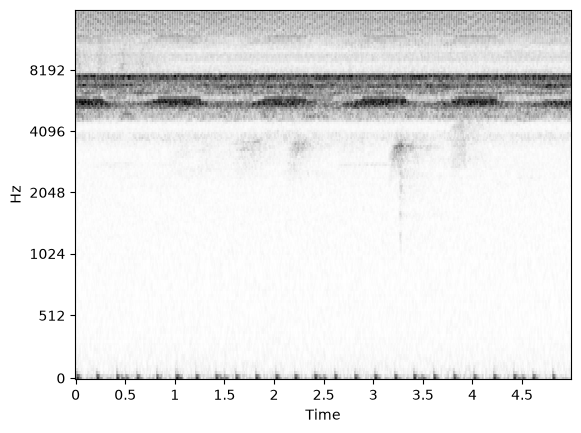

dataset name : osa
source uri   : swamp/sw2/1Jsw2_20261010_012000.wav
offset_s     : 20.00
rank         : 2
score        : -0.00


GridspecLayout(children=(Button(description='DENEBR', layout=Layout(grid_area='widget001'), style=ButtonStyle(…


--------------------------------------------------------------------------------


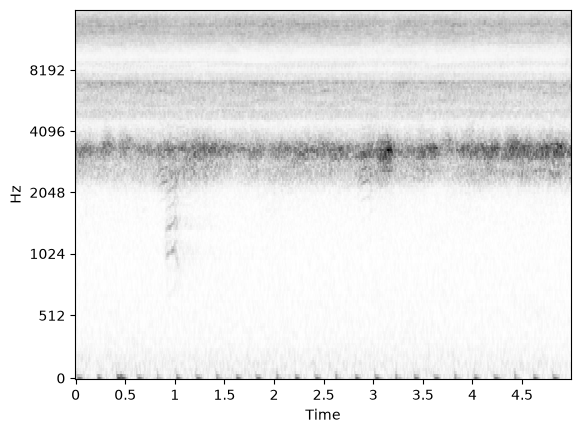

dataset name : osa
source uri   : swamp/sw1/1Jsw1_20260917_221400.wav
offset_s     : 25.00
rank         : 3
score        : -0.00


GridspecLayout(children=(Button(description='DENEBR', layout=Layout(grid_area='widget001'), style=ButtonStyle(…


--------------------------------------------------------------------------------


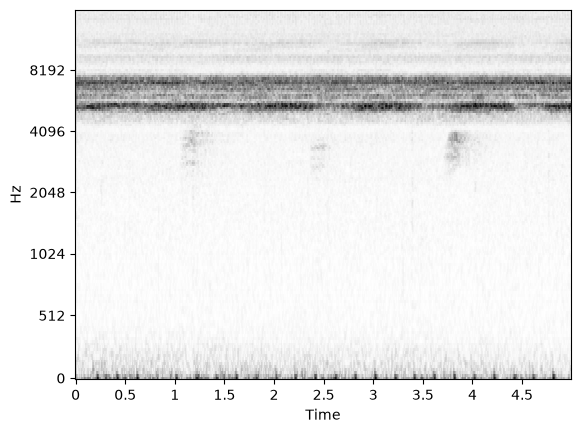

dataset name : osa
source uri   : swamp/sw2/1Jsw2_20261008_032000.wav
offset_s     : 0.00
rank         : 4
score        : -0.00


GridspecLayout(children=(Button(description='DENEBR', layout=Layout(grid_area='widget001'), style=ButtonStyle(…


--------------------------------------------------------------------------------
Page 1 of 1


Button(description='Prev Page', style=ButtonStyle())

Button(description='Next Page', style=ButtonStyle())

In [37]:
# @title Display the new results for labeling {vertical-output: true}

display_results = embedding_display.EmbeddingDisplayGroup.from_search_results(
    results,
    db,
    sample_rate_hz=SAMPLE_RATE,
    frame_rate=100,
    audio_loader=audio_filepath_loader,
)
display_results.display(positive_labels=[target_label])

#### Add selected results to the labeled data

As before, once we've annotated the examples from the previous cell, we'll save them in the `labeled_data_dir`.

In [38]:
# @title Save the new labels {vertical-output: true}

print('Annotations before saving :', len(db.get_all_annotations()))

db.insert_annotations(
    display_results.harvest_labels(annotator_id),
    handle_duplicates='skip',
)
db.commit()

print('Annotations after saving  :', len(db.get_all_annotations()))
print('\nNow go back and retrain the classifier with this extra data.')

Annotations before saving : 28
Annotations after saving  : 31

Now go back and retrain the classifier with this extra data.


### Repeat!

We now have two distinct methods for generating training data.  Keep looping through those two methods and training new linear models until you have a model you're happy with (a high AUC-ROC score is a good indicator of model quality).

**Note:** to start completely fresh, delete the database folder (`/content/powdermill_db`) and re-run the notebook from the *Connect to the embedding database* cell — the database holds both the embeddings and every label you have saved.

### Write the detections to CSV

The point of building the classifier is to apply it to far more audio than anyone could listen to. This cell runs it over the whole embedding database and writes every detection above `logit_threshold` to a CSV.

**`logit_threshold` is the most consequential number in this notebook, and it is not a technical choice — it is a decision about what kind of mistake you would rather make.**

* A **low** threshold catches more real vocalizations (high recall) and admits more false alarms. Right when the cost of missing something is high and every detection will be checked by a human: screening for a rare or endangered species, or looking for the first arrival of an invasive one.
* A **high** threshold means most detections are genuine (high precision) but you miss the quiet and distant ones. Right when detections feed directly into a number nobody will verify by hand: an occupancy estimate, a population trend, a habitat comparison across sites.

There is no universally correct value. `1.0` is a starting point, not an answer. In a real programme you would choose it by labeling a random sample of detections, measuring the precision and recall you actually get at several thresholds, and picking the trade-off that matches the decision the output will feed.

Notice what that implies: **you cannot choose a threshold without knowing what the results are for.** A model handed over without that context is not finished, however good its ROC-AUC.

In [ ]:
# @title Run inference over the whole corpus {vertical-output: true}

# @markdown Where to write the detections.
output_csv_filepath = '/content/inference.csv'  # @param {type: 'string'}

# @markdown Minimum logit to record. See the discussion above - this is a
# @markdown decision about false positives versus missed detections.
logit_threshold = 1.0  # @param {type: 'number'}

classifier.write_inference_csv(
    linear_classifier,
    db,
    output_csv_filepath,
    logit_threshold,
    labels=None,
    window_ids=db.match_window_ids(),
)

import pandas as pd
detections = pd.read_csv(output_csv_filepath)
print(f'\nWrote {len(detections)} detections to {output_csv_filepath}')
print(f'That is {len(detections)} windows out of {db.count_embeddings()} '
      f'({100 * len(detections) / max(db.count_embeddings(), 1):.1f}% of the '
      'corpus).')
detections.head(10)

## Visualization of results

We will now use [t-SNE](https://en.wikipedia.org/wiki/T-distributed_stochastic_neighbor_embedding) to produce a scatter plot of all of the embeddings.
t-SNE is a technique for reducing high-dimensional data to two dimensions
for visualization. It tries to keep points which are close in the embedding
space close in the two-dimensional space.

We will also use the output probabilities from the classifier to color the
resulting scatter plot.

In [ ]:
# @title Visualize the embedding space {vertical-output: true}

import sklearn.decomposition
from sklearn.manifold import TSNE

window_ids = db.match_window_ids()
all_embeddings = db.get_embeddings_batch(window_ids)
all_logits = linear_classifier(all_embeddings)
target_logits = all_logits[:, target_label_idx]

print(f'Projecting {all_embeddings.shape[0]} embeddings of dimension '
      f'{all_embeddings.shape[1]} down to 2D...')

# PCA first (fast, keeps most of the variance), then t-SNE for the layout.
n_components = min(256, all_embeddings.shape[0] - 1, all_embeddings.shape[1])
reduced = sklearn.decomposition.PCA(n_components).fit_transform(all_embeddings)
projected = TSNE(perplexity=min(30, max(5, len(reduced) // 4))).fit_transform(
    reduced)


def sigmoid(x):
  return 1 / (1 + np.exp(-x))


plt.figure(figsize=(10, 10))
plt.title(f'Powdermill embeddings, coloured by P({target_label})', fontsize=16)
plt.xticks([])
plt.yticks([])
scatter = plt.scatter(projected[:, 0], projected[:, 1],
                      c=sigmoid(target_logits), cmap='plasma',
                      alpha=0.5, marker='o')
plt.colorbar(scatter, label=f'P({target_label})', shrink=0.7)
plt.show()

print('Each point is five seconds of audio. Points that sit near each other '
      'sound similar to the model.')
print('If the classifier is working, the bright points should form clusters '
      'rather than being scattered at random.')

<a name="discussion"></a>
# Discussion

This pipeline provides end-to-end annotation of a large unlabeled dataset based on a particular class (in our case, a species) of interest. To recap, we processed an unlabeled soundscape dataset through user-in-the-loop active learning to produce windowed annotations, and concluded by writing the annotated data to CSV. This allows for a variety of downstream analysis and visualization.

## From a working model to an ecological decision

You now have a classifier. It is worth being precise about what that does and does not entitle you to conclude, because the gap between "the model works" and "we should act on this" is where most applied ML in conservation actually fails.

### Who uses this, and for what

The output of this workflow — timestamped detections with confidence scores — feeds four broad kinds of decision, and each demands something different from the model.

| Use case | Who uses it | What they need from the model | What "good enough" looks like |
| --- | --- | --- | --- |
| **Species presence** — is this species here at all? | Reserve managers, environmental consultants, regulators | High recall. A missed detection means concluding a species is absent when it is not. | Every positive detection verified by a human. Precision matters less because the volume is small and the cost of checking is low. |
| **Population monitoring** — is it becoming more or less common? | Ecologists, long-term monitoring programmes | Stable, *calibrated* detection rates over time. | Consistency matters more than accuracy. A model that misses 30% of calls is usable for trends **if** it misses the same 30% every year. One that drifts is not. |
| **Habitat disturbance** — did logging, a road, or a fire change the soundscape? | Land managers, impact assessors | Comparable performance across sites and conditions. | The model must not perform differently in the disturbed and control sites for reasons unrelated to the birds — different background noise alone can produce a fake effect. |
| **Conservation action** — halt work, change protection status, direct funding | Agencies, NGOs, landowners | Defensible, auditable evidence. | Human verification of the detections the decision rests on, documented methods, and known error rates. A confidence score is not evidence. |

Notice that **no single accuracy number answers "is this good enough?"** The same classifier can be entirely adequate for directing a field team's attention and entirely inadequate for a regulatory filing. The question is never "is the model accurate" but "is the model accurate enough *for this decision*, given what happens if it is wrong."

### What happens if it is wrong

Both errors carry real costs, and they are not symmetrical:

* **False negatives** — the species is present but not detected. A site is cleared for development on the strength of a survey that missed the birds. This is the error that quietly does harm, because nobody ever finds out.
* **False positives** — the species is reported where it is absent. Protection is applied to the wrong parcel, monitoring effort is misdirected, and if it is later discovered, the credibility of the whole monitoring programme takes the damage — including its correct results.

Which one you should tolerate is a question for the people who bear the consequences, not for the person tuning the threshold. That conversation belongs at the start of a project, not after the model is built.

### What this tutorial has not shown you

The workflow here takes you from one example recording to a working classifier in under an hour. That is genuinely useful, and it is genuinely not a deployment. Before any of the decisions above, you would still need to:

1. **Validate on a random sample**, not on your search results. Take a random selection of windows from the corpus, label them blind, and measure precision and recall there. This is the single most important step, and the one most often skipped.
2. **Test on data from somewhere else** — a different site, a different season, a different recorder — to find out whether performance survives the move.
3. **Have a domain expert review the detections.** Not all of them; a sample large enough to estimate the error rate.
4. **Write down the error rates** alongside any number you report. A detection count without an error rate is not a measurement.
5. **Decide who checks the model over time**, and how often. Models do not degrade visibly.

## Limitations

This method works well across a wide range of bioacoustic signals — see [Feature Embeddings from Large-Scale Acoustic Bird Classifiers Enable Few-Shot Transfer Learning](https://arxiv.org/abs/2307.06292). But it has real limits, and several of them are invisible from inside this notebook.

### Limits of this tutorial specifically

**We used 30 minutes of audio, not 6.4 hours.** A subset chosen to keep the tutorial fast. Real surveys are orders of magnitude larger, and the rare events that matter most are precisely the ones a subset is likely to omit.

**Your evaluation set is not a random sample.** This is the most important caveat here. You found your training data by searching for clips similar to your query and labeling what you recognised. The held-out examples come from that same enriched pool. The reported ROC-AUC therefore measures how well the model separates *the kinds of clips you chose to look at* — not how it behaves on the long, quiet, ordinary stretches that make up most of a soundscape. **Field performance is normally worse, sometimes considerably.**

**One species, one site, two recording days, one season.** Nothing here tests whether any of it generalises.

### Limits that persist in real deployments

**Noisy field recordings.** Rain, wind, insects, traffic, aircraft, and rubbing vegetation all degrade detection, and they do so unevenly — a recorder near a stream is quietly handicapped for its whole deployment. Distance matters too: a bird 50 metres away produces a fainter, more distorted signal than the same bird at 5 metres, and the model sees these as meaningfully different sounds.

**Class imbalance.** In a typical soundscape the target species is present in well under 1% of windows. At that base rate, a classifier with 99% precision on a balanced test set can still return mostly false positives in the field. This is not a flaw in the model — it is what conditional probability does at low prevalence, and it surprises people constantly.

**Rare species.** The species most worth monitoring are usually the ones with the fewest recordings, and this workflow needs at least one good example to search with. For the rarest species that recording may not exist, may be poor quality, or may capture only one of several call types. Agile modeling reduces how much labeled data you need; it does not reduce it to zero.

**Geographic transferability.** Regional dialects are real in many songbirds, and a model tuned on Pennsylvania Wood Thrushes may perform worse elsewhere in the range. Background soundscapes differ too — a classifier that learned to separate its target from *this* forest's noise has partly learned the noise.

**Seasonal and temporal variation.** Powdermill is dawn chorus in breeding season, when birds sing most and most distinctively. The same species is quieter, and sings differently or not at all, outside that window. Juveniles sound different from adults. A model built on spring dawn recordings should not be assumed to work in autumn, at midday, or at night.

**Train/deployment mismatch.** The embedding model was trained largely on Xeno-Canto **focal** recordings — someone pointing a directional microphone at a single bird, close, clear, deliberately captured. Your corpus is **passive** monitoring: an omnidirectional recorder strapped to a tree, capturing everything at once. The transfer works well, which is the point of the paper above, but it is a genuine domain shift and it is where quiet or overlapping calls are lost.

**Recorder and settings differences.** Different hardware, gain settings, sample rates, and compression all shift the input. A model validated on one recorder type has not been validated on another.

**Annotator variation.** Your labels reflect your ear, your care, and your tolerance for uncertainty on the day. Two annotators rarely agree completely, and a model trained on one person's labels inherits that person's biases. This is why every annotation here is stored with an `annotator_id`.

### When to use a different approach

If performance stays poor after several rounds of labeling, the problem is often the **representation, not the classifier**. Try a different embedding model — `perch-hoplite` also ships BirdNET, Perch 2.0, and SurfPerch (reef sounds) presets. Note that embeddings from different models are not comparable, so switching means starting a fresh database (`db_path`) and re-embedding the audio from the setup section onward. For very noisy audio, [unsupervised sound separation](https://arxiv.org/abs/2110.03209) as a preprocessing step can improve retrieval substantially.

## Responsible use

**What this workflow is for:** helping experts search large volumes of audio far faster than they could by listening, and building custom detectors for sounds that no off-the-shelf classifier covers.

**What it is not for:**

* **Producing detection counts nobody verifies.** The output is a set of candidates with confidence scores. Treating it as a census is the most common misuse of this class of tool.
* **Regulatory or legal claims without expert review.** "The model found no Wood Thrush" is not evidence of absence, and should never be presented as such in an impact assessment.
* **Comparing sites or years without checking that the model behaves the same in each.** Apparent ecological differences are often model artefacts.
* **Monitoring humans.** These recorders capture speech. See below.

### Privacy

Passive acoustic monitors record whatever is audible, including human conversation. In many jurisdictions that carries legal obligations, and it carries ethical ones everywhere. Recordings from populated or publicly accessible areas need a retention policy, access controls, and — where people may reasonably expect privacy — consent or signage. This is a real and frequently overlooked consideration in bioacoustic programmes, not a hypothetical.

### Data sovereignty

Bioacoustic monitoring often happens on Indigenous or community-managed land. Who owns the recordings, who may access them, and who decides what is published are questions to settle before deployment, not after. Species-occurrence data can be sensitive in its own right: publishing precise locations of a rare species has, in documented cases, aided poachers and collectors.

### Being honest about uncertainty

The tool offers an "uncertain" label and then discards those clips rather than guessing. That design choice is worth carrying into your own practice. An annotation set that records genuine doubt as doubt is more useful than one where every hesitation has been quietly resolved into a yes or a no — and a model trained on the latter will confidently reproduce judgements nobody actually made.

### Documentation as a responsibility

If detections from a model like this inform a decision, someone should be able to reconstruct later how those detections were produced: which model, which query, who labeled the training data, what threshold, and what the measured error rates were. The datasheet and model card below are a starting template for that record.

## Next Directions

If you would like to apply these methods to your own audio dataset, the tools here should provide enough guidance to get started! For large datasets, you will want to use a GPU to compute the embeddings. And for very large datasets, we provide tooling for processing audio into embeddings with Apache Beam + Dataflow on GCP.


If you would like to try a different embedding model, our main codebase provides tools to do so. We provide an abstract EmbeddingModel class, which allows us to use any model that can turn a window of audio into an embedding.


There are a wide variety of problems to consider in this space!

* Detection of specific call types for a species,
* Classifying adult/juvenile calls,
* Tracking changes in vocalization patterns over time and geography,
* Tracking the impact of anthropogenic noise on an ecosystem,
* Broad biodiversity measurements,
* Directly classifying 'ecosystem health' from audio samples.

And more! Really, the only limit is your imagination!


## Datasheet: the datasets used

Following the structure proposed in [Datasheets for Datasets](https://arxiv.org/abs/1803.09010).

### Powdermill Nature Reserve soundscapes (the search corpus)

| Field | Detail |
| --- | --- |
| **Purpose** | Published to support development and evaluation of bird sound detection in passive recordings. |
| **Contents** | ~6.4 hours of dawn chorus soundscape audio from Powdermill Nature Reserve, Pennsylvania, USA, in four recording days, with expert annotations. This tutorial uses 30 minutes blended from two recording days (one song-dense and one sparse file from Recording_2, four Wood-Thrush-free files from Recording_4), chosen with the expert annotations so that high similarity scores correspond to real songs and low scores to genuine absence. |
| **Collection** | Passive acoustic monitoring — fixed omnidirectional recorders, capturing everything audible. Not targeted at individual birds. |
| **Annotations** | Expert-labeled with species, time, and frequency bounds. Supplied as Raven selection tables and a consolidated CSV. |
| **Licence** | CC-0 (public domain). |
| **Source** | [Zenodo record 4656848](https://zenodo.org/record/4656848); mirrored at `gs://chirp-public-bucket/soundscapes/powdermill`. |
| **Citation** | Chronister, L. M., Rhinehart, T. A., Place, A., & Kitzes, J. (2021). *An annotated set of audio recordings of Eastern North American birds containing frequency, time, and species information.* |
| **Known limitations** | A single site, a single season, dawn chorus only, temperate Eastern North American species. Not representative of tropical, nocturnal, marine, or arid soundscapes. Species distribution is heavily imbalanced. |
| **Preprocessing here** | Resampled to 32 kHz, split into non-overlapping 5-second windows. Only a subset is used, for speed. |
| **Sensitive content** | Passive recordings from a nature reserve. Human speech is possible in principle; none is used here. |

### Xeno-Canto (used to train the embedding model, and for the query)

| Field | Detail |
| --- | --- |
| **Purpose** | A community-contributed archive of wildlife sound recordings from around the world. |
| **Contents** | Hundreds of thousands of **focal** recordings — a recordist deliberately capturing a single identified bird. |
| **Collection** | Volunteer contributions, varying equipment, technique, and conditions. |
| **Licence** | Per-recording Creative Commons variants. Check individual recordings before redistribution. |
| **Source** | [xeno-canto.org](https://xeno-canto.org/) |
| **Known limitations** | **Strong geographic and species bias** toward regions with many active recordists — Europe and North America are far better covered than the tropics, where biodiversity is greatest. Focal recordings differ systematically from passive monitoring audio: closer, cleaner, higher signal-to-noise, and the target species is nearly always present. Species identifications are contributor-supplied and occasionally wrong. |
| **Role here** | The embedding model was pre-trained on this data. The query clip (`xc105133`) also comes from it. |

## Model card

Following the structure proposed in [Model Cards for Model Reporting](https://arxiv.org/abs/1810.03993). Two models are involved.

### 1. Perch / Bird Vocalization Classifier v8 (the embedding model)

| Field | Detail |
| --- | --- |
| **Developer** | Google DeepMind / Google Research (Perch team) |
| **Version** | `perch_8` — version 8 on Kaggle Models |
| **Input** | 5 seconds of audio at 32 kHz |
| **Output** | A 1280-dimensional embedding, plus species logits (unused here) |
| **Training data** | Xeno-Canto focal recordings, ~10,000 bird species |
| **Intended use** | A general-purpose representation for bioacoustic tasks, especially few-shot transfer |
| **Use here** | Feature extractor only. We never use its species predictions — we use its learned representation. |
| **Performance** | Embeddings transfer effectively to novel bioacoustic problems including call types, bats, and marine mammals, outperforming general audio models ([arXiv:2307.06292](https://arxiv.org/abs/2307.06292)) |
| **Limitations** | Trained on birds — non-bird sounds are further out of distribution. Focal-to-passive domain shift. Species coverage follows Xeno-Canto's geographic bias, so tropical species are less well represented. |
| **Licence** | See the [Kaggle model page](https://www.kaggle.com/models/google/bird-vocalization-classifier) |

### 2. The linear classifier you trained

| Field | Detail |
| --- | --- |
| **Developer** | You, in this notebook |
| **Architecture** | A single linear layer over 1280-dimensional embeddings |
| **Training data** | The handful of examples you labeled — typically 10–30 windows |
| **Training procedure** | 128 steps, learning rate 1e-3, binary cross-entropy, unlabeled search results treated as weak negatives at weight 0.05 |
| **Intended use** | **Demonstration and exploratory search within this corpus only.** |
| **Out of scope** | Any use outside this notebook without revalidation. Not suitable for population estimates, regulatory filings, or any decision affecting land use or protection status. |
| **Evaluation** | Held-out examples from the labeled pool. **This overstates field performance** — see Limitations. |
| **Ethical considerations** | Trained on one person's labels in one session. Inherits that annotator's biases and any errors in the query recording's identification. |
| **Caveats** | Performance depends heavily on the query window chosen, and on how carefully the labeling was done. Two participants following this notebook will produce measurably different classifiers. |

### Provenance recorded automatically

Every annotation is stored with its `annotator_id`, and the embedding configuration is stored inside the database. If detections from this model were ever questioned, that record is what would let someone reconstruct how they were produced.

# References

Perch [opensourced codebase](https://github.com/google-research/perch)

Open-sourced Datasets:
*    [Xeno-Canto](https://xeno-canto.org/)
*    [Powdermill Soundscape dataset](https://zenodo.org/record/4656848#.Y7ijhOxudhE)

Pre-trained embedding model for other transfer learning tasks:
*    [Bird Vocalization Classifier v4](https://tfhub.dev/google/bird-vocalization-classifier/4)

Related research:
* "Feature Embeddings from Large-Scale Acoustic Bird Classifiers Enable Few-Shot Transfer Learning" ([arXiv](https://arxiv.org/abs/2307.06292))
* "Agile Modeling: From Concept to Classifier in Minutes" ([arXiv](https://arxiv.org/abs/2302.12948))